# M0 to M2 on IEEE-CIS

## 1. Introduction
This notebook implements and evaluates the first three stages of credit card fraud detection on the IEEE-CIS dataset, for logistic regression (LR), random forest (RF) and CatBoost. The stages progressively address key challenges in fraud detection: severe class imbalance, transaction patterns that change over time, and delays in fraud-label verification

The experiments are organised into three stages:
- **M0 – Baseline Models**: establish reference performance using LR, RF and CatBoost without class-imbalance adjustments. This is the baseline that every later stage is compared with

- **M1 – Cost-Sensitive Learning**: introduce class weights to increase the penalty for misclassifying fraudulent transactions. M0 and M1 use the same features, preprocessing (Section 2.4) and settings (Section 4), and M1 only adds class weights => the difference between them shows the effect of class weights on its own

- **M2 – Periodic Retraining** (Section 9): investigate whether regularly updating the models using recent labelled transactions improves robustness to changes over time, while accounting for a 7-day label verification delay. M2 is built on whichever of M0 and M1 does better

The notebook also covers some checks that are specific to IEEE-CIS:
- **Seed check** (Section 5.6): we refit RF and CatBoost with two more seeds, to see whether the gaps between models are bigger than the noise from the random seed

- **Card history check** (Section 6): we refit each M0 model without the card-history features. In IEEE-CIS, once a card has a chargeback, its later transactions are also labelled fraud, so features that recognise a card could raise the score without describing the transaction itself. The raw and reconstructed card IDs are never model inputs

- **SHAP** (Section 8): SHAP values for the M0 CatBoost model

Models are evaluated using chronological data partitions to reflect the temporal nature of fraud detection and avoid the optimistic estimates that may arise from random train-test splitting. Precision-Recall AUC (PR-AUC) is the primary metric because of the low share of fraud (about 3.5% of the transactions, Section 3), supplemented by ROC-AUC, precision, recall, F1 and precision@100 per day

Tuning and feature selection are done after M2, so that each step from M0 to M2 only changes one thing, and the settings are tuned for the way the final model is retrained

The features come from `04_feature_engineering.ipynb` (saved in `data/processed/`). We only use the training and validation rows here. The test rows are reserved for the final evaluation, which is run once after model development, when all choices are fixed

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from catboost import CatBoostClassifier, Pool
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

SEED = 100
PROCESSED_DIR = Path("../data/processed")

## 2. Data Loading and Preparation
We load the processed features, prepare the training and validation sets, check how much of each feature is missing, and set up the model-specific preprocessing for each family

### 2.1 Load Processed Features
The processed IEEE-CIS features are loaded from the feature-engineering pipeline (notebook 04, run notebooks 03 and 04 first if these files are missing). They contain transaction-level characteristics, the anonymised `C`, `D`, `M`, `V` and `id_` columns, and historical card behaviour by `card_id`, including rolling-window transaction counts and amounts
- A predefined list of 575 modelling features (`ieee_feature_cols`) is loaded separately to exclude transaction identifiers, card IDs, raw timestamps, target labels and other non-predictive columns. The card IDs are only used to build features

- The dataset keeps the chronological training, validation and test splits. Their sizes and days are examined to see the class distribution across the evaluation periods, and the fraud rate is only shown for the training and validation rows

In [2]:
features = pd.read_pickle(PROCESSED_DIR / "ieee_features.pkl")
with open(PROCESSED_DIR / "feature_lists.json") as f:
    feature_lists = json.load(f)

feature_cols = feature_lists["ieee_feature_cols"]

# rows and days in each split (no fraud rate for the test rows, they stay aside)
split_day = features["TransactionDT"] // 86400
split_table = pd.DataFrame({"rows": features.groupby("ieee_split").size(),
                            "first day": split_day.groupby(features["ieee_split"]).min(),
                            "last day": split_day.groupby(features["ieee_split"]).max()}).loc[["train", "validation", "test"]]
fraud_rate = features.groupby("ieee_split")["isFraud"].mean().reindex(split_table.index) * 100
split_table["fraud rate (%)"] = fraud_rate.round(2).where(split_table.index != "test")
display(split_table)
del split_day, fraud_rate

,rows,first day,last day,fraud rate (%)
ieee_split,,,,
train,377945,1,109,3.41
validation,94487,109,141,3.92
test,118108,141,182,NaN


### 2.2 Prepare Training and Validation Sets
The dataset is split using the predefined chronological split labels. The training rows are used for model fitting, and the validation rows are used for model comparison
- Predictor variables (`X`) are separated from fraud labels (`y`), and the categorical and numeric features are identified for the model-specific preprocessing (Section 2.4):
    - missing values in categorical columns are replaced with the text `"missing"`, and these columns are stored as pandas categories (the models use this data type to find the categorical columns)
    - `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are stored as numbers **BUT** their values are codes => we turn them into text categories here e.g. 315.0 becomes `"315"` and a missing value becomes `"missing"`, so every model will see them as categories
    - numeric columns are stored as float32

- Only the training and validation rows are kept, so the test rows are excluded from model development and never reach a model => this prevents information leakage into model selection

In [3]:
# these columns are stored as numbers, but the numbers are codes with no order
CODE_AS_CATEGORY = ["card1", "card2", "card3", "card5", "addr1", "addr2"]

cat_cols = [c for c in feature_cols if c in feature_lists["ieee_categorical_cols"] or c in CODE_AS_CATEGORY]
num_cols = [c for c in feature_cols if c not in cat_cols]

# keep only the needed columns, and only the training and validation rows
keep = feature_cols + ["isFraud", "ieee_split", "TransactionDT"]
features = features.loc[features["ieee_split"].isin(["train", "validation"]), keep]
features[num_cols] = features[num_cols].astype("float32")
for col in cat_cols:
    if col in CODE_AS_CATEGORY:
        # numbers to text codes e.g. 315.0 becomes "315" and a missing value becomes "missing"
        numbers = pd.to_numeric(features[col], errors="coerce")
        values = numbers.to_numpy(dtype="float64")
        rounded = np.round(values)
        whole = np.isfinite(values) & np.isclose(values, rounded)
        text = np.full(len(features), "missing", dtype=object)
        text[whole] = rounded[whole].astype("int64").astype(str)
        other = np.isfinite(values) & ~whole   # not a whole number => keep the value
        text[other] = numbers.to_numpy(dtype=object)[other]
        features[col] = pd.Series(text, index=features.index).astype("category")
    else:
        features[col] = features[col].astype("object").fillna("missing").astype(str).astype("category")

train = features[features["ieee_split"] == "train"]
val = features[features["ieee_split"] == "validation"]
del features

X_train, y_train = train[feature_cols], train["isFraud"]
X_val, y_val = val[feature_cols], val["isFraud"]
val_day = (val["TransactionDT"] // 86400).to_numpy()

print("training rows:", len(train), "| fraud rate:", round(y_train.mean() * 100, 2), "%")
print("validation rows:", len(val), "| fraud rate:", round(y_val.mean() * 100, 2), "% | days:", len(np.unique(val_day)))
print("features:", len(feature_cols), "| numeric:", len(num_cols), "| categorical (with the 6 code columns):", len(cat_cols))

training rows: 377945 | fraud rate: 3.41 %
validation rows: 94487 | fraud rate: 3.92 % | days: 33
features: 575 | numeric: 528 | categorical (with the 6 code columns): 47


### 2.3 Missing-Value Assessment
Before model training, we examine missing values across the 575 selected features to decide whether preprocessing is needed. In IEEE-CIS many columns are only filled for some transactions (e.g. the `id_` columns only exist for transactions with identity data, and the `V` columns come in blocks that are missing together). Historical card features can also be missing when there is not enough earlier card activity to calculate them
- Missing shares are calculated separately for the training and validation rows, to find the affected features and check whether their missingness changes over time => a feature whose missing share changes a lot can make the model worse on later days

- A numeric value counts as missing if it is NaN, and a categorical value counts as missing if it is the `"missing"` category from Section 2.2

- Rather than removing incomplete rows straight away, we first look at how much is missing and where. The preprocessing is then chosen based on each family's requirements (Section 2.4), and any imputation values are learned from the training rows only to prevent information leakage

In [4]:
# share of missing values per feature: NaN for numeric columns, the "missing" category for categorical columns
def missing_share(X):
    numeric_share = X[num_cols].isna().mean()
    categorical_share = pd.Series({c: (X[c] == "missing").mean() for c in cat_cols})
    return pd.concat([numeric_share, categorical_share])[feature_cols]


missing = pd.DataFrame({"train": missing_share(X_train), "validation": missing_share(X_val)})
missing["change"] = missing["validation"] - missing["train"]

labels = ["none", "up to 10%", "10% to 50%", "50% to 90%", "over 90%"]
buckets = pd.DataFrame({split: pd.cut(missing[split], [-0.001, 0, 0.1, 0.5, 0.9, 1], labels=labels).value_counts().reindex(labels)
                        for split in ["train", "validation"]})
print("number of features by share of missing values:")
display(buckets)

print("rows with at least one missing feature:", round(X_train[num_cols].isna().any(axis=1).mean() * 100, 1), "% of training rows")

print("10 features with the most missing values in the training rows:")
display((missing.sort_values("train", ascending=False).head(10) * 100).round(1))

print("10 features whose missing share changes most from training to validation (percentage points):")
display((missing.reindex(missing["change"].abs().sort_values(ascending=False).index).head(10) * 100).round(1))

number of features by share of missing values:


,train,validation
none,116,104
up to 10%,77,135
10% to 50%,119,104
50% to 90%,251,157
over 90%,12,75


rows with at least one missing feature: 100.0 % of training rows
10 features with the most missing values in the training rows:


,train,validation,change
id_24,99.1,99.4,0.3
id_25,99.0,99.4,0.3
id_08,99.0,99.4,0.3
id_07,99.0,99.4,0.3
id_26,99.0,99.4,0.3
id_21,99.0,99.4,0.4
id_22,99.0,99.4,0.3
id_27,99.0,99.4,0.3
id_23,99.0,99.4,0.3
D7,93.7,93.3,-0.4


10 features whose missing share changes most from training to validation (percentage points):


,train,validation,change
M8,69.4,39.7,-29.7
M9,69.4,39.7,-29.7
M7,69.4,39.7,-29.7
M3,55.9,28.5,-27.5
M1,55.9,28.5,-27.5
M2,55.9,28.5,-27.5
V7,56.8,33.0,-23.8
V3,56.8,33.0,-23.8
V2,56.8,33.0,-23.8
V4,56.8,33.0,-23.8


**Takeaway: Missing-Value Assessment**
- There are a lot of missing values. Every training row has at least one missing feature, and 263 of the 575 features are missing for more than half of the training rows. The most missing features are the `id_` columns (about 99%), since identity data only exists for some transactions, then `D7` (94%)

- These patterns are consistent with columns that are structurally undefined for many transactions (no identity record, or a block of `V` columns that does not apply) => removing incomplete rows would discard almost every transaction and could introduce selection bias

- The missing share changes over time. `M1` to `M3`, `M7` to `M9` and some `V` columns (e.g. `V2`, `V3`, `V4` and `V7`) are missing much less often in the validation rows (by 24 to 30 percentage points), while more features are almost empty in the validation rows (75 features over 90% missing, vs 12 in the training rows) => a missing value does not mean the same thing in every period, which is one more reason to retrain over time (M2, Section 9)

- **Final decision**: we retain all rows and columns and handle missing values through model-appropriate preprocessing (Section 2.4). RF and CatBoost handle missing values themselves, and LR fills them with the training median, which is applied in the same way to the validation rows. Whether a value is missing is itself information the trees can use

### 2.4 Model-Specific Preprocessing
Different families have different requirements for their inputs. To ensure a fair comparison across baseline models, preprocessing is tailored to each algorithm while maintaining identical training and validation partitions
- **LR**: categorical columns are one-hot encoded, numeric missing values are filled with the training median, and numeric columns are standardised to improve optimisation stability. Before standardising we also apply `arcsinh`, which works like a log for large values but is also defined at 0 and for negative values => this is important because many columns are very skewed and some `D` columns are negative. Categorical values with fewer than 100 training rows share one "infrequent" column (a weight learned from a few rows is mostly noise). The raw identity columns (e.g. `id_31`, `DeviceInfo`) are kept next to their cleaned versions (e.g. `id31_browser_family`, `device_brand`) => the cleaned ones give the general effect, and the raw ones add the effect of a specific common version or model. `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` are codes stored as categories (Section 2.2), so LR one-hot encodes them too. `card1` alone has about 12,000 codes => these six columns have their own one-hot encoder that only keeps codes with at least 500 training rows, and the rarer codes share one "infrequent" column

- **RF**: categorical columns are ordinal-encoded: each category gets an integer learned from the training rows, missing is its own category, and a category that never appears in the training rows gets -1. The six code columns are encoded the same way, so their integers follow the text order of the codes (e.g. `"1000"` comes before `"999"`) and not their size. RF still splits on thresholds of these integers => one split puts a group of neighbouring codes on each side, which has no real meaning, and RF needs two splits to single out one `card1` value. CatBoost does not have this problem, since its target statistics give each code its own fraud rate (Section 4.3). Numeric columns are used as they are: standardising is not needed, because trees split on feature thresholds rather than distances, and neither is imputation, since RF handles missing numeric values itself

- **CatBoost**: supports categorical features directly and handles missing numeric values itself, so the numeric columns are used without scaling or imputation, and missing categorical values are already the `"missing"` category (Section 2.2) => no preprocessing step is needed, and the categorical columns are passed to CatBoost when it is fitted (Section 4.3)

All learned preprocessing (medians, scaling and encoders) is fitted on the training rows only and then applied to the validation rows, to prevent information leakage. No class weights or resampling are used in M0, so M0 is an unadjusted baseline that the cost-sensitive M1 models can be compared with

The code below builds the LR and RF preprocessing. Each one is put in one pipeline with its model in Section 4, so the validation rows do not influence model fitting

In [5]:
numeric = make_column_selector(dtype_exclude="category")
categorical = make_column_selector(dtype_include="category")
code_pattern = r"^(?:card1|card2|card3|card5|addr1|addr2)$"
lr_codes = make_column_selector(pattern=code_pattern, dtype_include="category")   # the six code columns
lr_categorical = make_column_selector(pattern=r"^(?!(?:card1|card2|card3|card5|addr1|addr2)$)", dtype_include="category")   # all other categorical columns


# arcsinh without making another copy of the numeric columns (saves memory)
def arcsinh_in_place(X):
    return np.arcsinh(X, out=X)


# LR preprocessing: median imputation, arcsinh and standardising for numeric columns, one-hot encoding for categorical columns
lr_preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), FunctionTransformer(arcsinh_in_place), StandardScaler(copy=False)), numeric),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100, dtype=np.float32), lr_categorical),   # rare values go into one column
    ("codes", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=500, dtype=np.float32), lr_codes),   # rare codes go into one column
])

# RF preprocessing: numeric columns as they are, categorical columns ordinal-encoded (trees do not need scaling)
rf_preprocessor = ColumnTransformer([
    ("num", "passthrough", numeric),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categorical),
])

## 3. Evaluation Metrics
All models are scored on the validation rows with the same metrics. Each model's scores and training time are shown right after it is trained, and the full results table is in Section 7:
- **PR-AUC** (main metric): the area under the precision-recall curve, which does not depend on a threshold. A model that ranks transactions at random gets about the fraud rate, which is 0.039 on the validation rows, so this is the lowest score any model should get

- **ROC-AUC**

- **Precision, recall and F1** at a threshold of 0.5. We have not chosen a threshold yet, so 0.5 is just a default for now

- **Precision@100 per day**: for each validation day, we take the 100 transactions with the highest scores and calculate the share that are fraud, then average this over all validation days. 100 is about 3% of a day's transactions and stands for the number of cases a review team could check in one day

In [6]:
val_scores = {}   # validation scores of every model
train_time = {}   # training time of every model, in seconds
k = 100
metric_cols = ["PR-AUC", "ROC-AUC", "precision", "recall", "F1", f"precision@{k} per day"]


def evaluate(name, scores=None):
    scores = val_scores[name] if scores is None else scores
    predictions = (scores >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()

    # precision@k per day: share of fraud among each day's k highest scores, averaged over the days
    daily = pd.DataFrame({"day": val_day, "y": y_val.to_numpy(), "score": scores})
    top_k = daily.sort_values("score", ascending=False, kind="stable").groupby("day").head(k)

    return {"model": name,
            "PR-AUC": average_precision_score(y_val, scores),
            "ROC-AUC": roc_auc_score(y_val, scores),
            "precision": precision_score(y_val, predictions, zero_division=0),
            "recall": recall_score(y_val, predictions, zero_division=0),
            "F1": f1_score(y_val, predictions, zero_division=0),
            f"precision@{k} per day": top_k.groupby("day")["y"].mean().mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


# show the scores and training time of one or more models as a table
def show(*names):
    table = pd.DataFrame([evaluate(name) for name in names]).set_index("model").round(4)
    table["train time (s)"] = [round(train_time[name]) for name in names]
    display(table)

## 4. M0: Baseline Models
M0 establishes reference performance for fraud detection before introducing techniques for class imbalance or concept drift. Three supervised families are considered: LR, RF and CatBoost
- These families represent different levels of complexity, so we can see whether non-linear relationships and interactions between transaction features improve fraud detection compared with a linear baseline

- All models are trained on the same chronological training rows (about 3.4% fraud) and scored on the validation rows. The settings are common default values, and they are only tuned after M2

- No class weights or resampling are used in M0: every transaction has the same weight, so the models learn from the training rows as they are => a consistent reference for M1 and M2

- Each section below defines one family's model and its M0 settings. `models` keeps one unfitted model per family and `base_settings` keeps its M0 settings. For each run we copy the model with `clone` and only change the settings with `set_params` => M1 (Section 5) and M2 (Section 9) reuse the same models

### 4.1 Logistic Regression
LR is an interpretable linear baseline that estimates the probability of fraud from a weighted combination of the features (a weighted sum passed through a sigmoid) => it only learns effects that add up and cannot learn interactions by itself. It is fast and easy to read, so it shows how much the tree models add on top
- Preprocessing: numeric columns are median-filled, `arcsinh`-transformed and standardised, and categorical columns are one-hot encoded (`lr_preprocessor`, Section 2.4). These steps are in one pipeline, so the preprocessing is consistent and the validation rows do not influence model fitting

- Settings: L2 regularisation with `C` = 1 (the default), lbfgs with up to 2000 iterations, and default class weights. On all training rows M0 converges after about 400 iterations **BUT** M1 needs about 1,000 (Section 5.2) => with a limit of 1000, M1 stopped just before converging

- The predicted fraud probabilities are evaluated mainly with PR-AUC, with ROC-AUC as a second threshold-independent metric

In [7]:
# one unfitted model per family and its M0 settings, filled in Sections 4.1 to 4.3
models, base_settings = {}, {}

# M0: LR with L2 regularisation and default class weights
models["LR"] = make_pipeline(lr_preprocessor, LogisticRegression(max_iter=2000))   # M1 needs about 1,000 lbfgs iterations to converge on all training rows
base_settings["LR"] = {"logisticregression__C": 1.0}

start = time.time()
model = clone(models["LR"]).set_params(**base_settings["LR"])
model.fit(X_train, y_train)
val_scores["M0 LR"] = model.predict_proba(X_val)[:, 1]
del model
train_time["M0 LR"] = time.time() - start
show("M0 LR")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399,156


**Takeaway: M0 LR**
- The unweighted LR baseline gets a validation PR-AUC of **0.527** and ROC-AUC of **0.888**, with a training time of 156s

- This is far above the random-ranking baseline of 0.039 (the validation fraud rate) => the model ranks fraud decently despite the class imbalance, and the high ROC-AUC shows that fraudulent transactions generally get higher scores than legitimate ones

- At 0.5 it flags 1,724 transactions and catches 1,340 of the 3,704 frauds (precision 0.777, recall 0.362)

- Precision@100 per day 0.528 => about 53 of each day's 100 highest-scored transactions are fraud

- **BUT** threshold-independent metrics do not show how the model would do at a specific false-alarm rate or alert volume => these results are just a first reference for the comparisons with RF, CatBoost and class weights

### 4.2 Random Forest
RF is an ensemble that combines many decision trees to capture non-linear relationships and interactions between transaction features. Unlike LR, RF does not assume a linear relationship between the features and the log-odds of fraud, so it can model more complex behaviour (e.g. a large amount only being risky for one product type)
- Each tree is grown on a bootstrap sample of the training rows and picks from a random subset of the features at each split (the square root of the number of features) => the trees make different errors, so their average is more stable than one tree

- Preprocessing: categorical columns are ordinal-encoded and numeric columns are used as they are, with no imputation or standardising (`rf_preprocessor`, Section 2.4). These steps are in one pipeline with the model, so the encoder is learned from the training rows only

- Settings: 100 trees and a minimum leaf size of 20, to control the computational cost and reduce overfitting. Class weights stay off to keep the unadjusted M0 baseline

- The model is evaluated on the same chronological validation rows as LR, with PR-AUC and ROC-AUC, so the results can be compared

In [8]:
# M0: RF with 100 trees and default class weights
models["RF"] = make_pipeline(rf_preprocessor, RandomForestClassifier(n_estimators=100, max_features="sqrt", n_jobs=-1, random_state=SEED))
base_settings["RF"] = {"randomforestclassifier__min_samples_leaf": 20}

start = time.time()
model = clone(models["RF"]).set_params(**base_settings["RF"])
model.fit(X_train, y_train)
val_scores["M0 RF"] = model.predict_proba(X_val)[:, 1]
del model
train_time["M0 RF"] = time.time() - start
show("M0 RF")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653,139


**Takeaway: M0 RF**
- The unweighted RF gets a validation PR-AUC of **0.559** and ROC-AUC of **0.910**, outperforming LR (PR-AUC 0.527, ROC-AUC 0.888) => non-linear relationships and interactions between features add predictive value beyond a linear decision boundary

- RF is the most careful at 0.5: it flags only 1,168 transactions and catches 1,038 frauds (precision 0.889, recall 0.280)

- Precision@100 per day 0.556, and it trains faster than LR here (139s vs 156s)

### 4.3 CatBoost
CatBoost is a gradient-boosted decision tree algorithm that sequentially constructs trees to correct errors made by preceding iterations. Unlike Random Forest, which aggregates independently constructed trees, CatBoost uses boosting to progressively improve predictive performance
- CatBoost supports categorical features directly, so no one-hot encoding is needed. It uses ordered target statistics (the fraud rate of a category, calculated only from the rows before each row in a random order) => high-cardinality columns like `card1` can be used, and a row's own label is not used to encode it

- Preprocessing: none (Section 2.4). The numeric columns are used without scaling or imputation, since CatBoost handles missing numeric values itself, and missing categorical values are already the `"missing"` category

- Settings: depth 6, 500 trees and a learning rate of 0.1. Class weights stay off, for comparability with the unweighted LR and RF baselines. `allow_writing_files=False` only stops CatBoost from writing log files and does not change the model

- The model is trained on the same chronological training rows and evaluated with PR-AUC and ROC-AUC on the validation rows

In [9]:
# M0: CatBoost with categorical features passed directly and default class weights
models["CatBoost"] = CatBoostClassifier(learning_rate=0.1, random_seed=SEED, thread_count=-1, verbose=0, allow_writing_files=False)
base_settings["CatBoost"] = {"depth": 6, "iterations": 500}

start = time.time()
model = clone(models["CatBoost"]).set_params(**base_settings["CatBoost"])
model.fit(X_train, y_train, cat_features=cat_cols)
val_scores["M0 CatBoost"] = model.predict_proba(X_val)[:, 1]
shap_model = model   # kept for SHAP in Section 8
train_time["M0 CatBoost"] = time.time() - start
show("M0 CatBoost")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392,717


**Takeaway: M0 CatBoost**
- The unweighted CatBoost gets a validation PR-AUC of **0.626** and ROC-AUC of **0.926**, outperforming both LR and RF => **the best M0 model** (0.067 PR-AUC above RF)

- At 0.5 it flags 2,056 transactions and catches 1,665 frauds (precision 0.810, recall 0.450) => the highest recall and F1 (0.578) of the three

- Precision@100 per day 0.612. It is the slowest to train (717s, about 12 minutes), vs 139s for RF and 156s for LR

- Gradient-boosted trees seem to capture the complex relationships between transaction characteristics and card behaviour best

### 4.4 Baseline Model Comparison
The three M0 models side by side

In [10]:
show("M0 LR", "M0 RF", "M0 CatBoost")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399,156
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653,139
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392,717


**Takeaway: M0**
- **CatBoost is the strongest M0 baseline**, with the highest PR-AUC (0.626) and ROC-AUC (0.926), followed by RF (PR-AUC 0.559) and LR (0.527) => non-linear models are better at capturing the complex relationships and interactions linked to fraud. CatBoost is also the best on precision@100 per day (0.612, so about 61 of each day's 100 highest-scored transactions are fraud)

- All three are far above the random baseline of 0.039, so even LR with default settings ranks fraud decently

- At the 0.5 threshold all three are careful: precision is high (0.78 to 0.89) **BUT** recall is low (0.28 to 0.45) => most fraud gets a score below 0.5, so 0.5 is too high as a threshold here. The threshold is chosen later, using an assumed investigation cost

- RF has the highest precision (0.889) and the lowest recall (0.280) at 0.5, so it flags the fewest transactions (1,168)

- Training time: LR 156s, RF 139s, CatBoost 717s. CatBoost gives the best results but is the slowest, which matters for M2, where the models are retrained many times

- These results are the unweighted benchmarks for M1. In M1, class weights are added while the chronological split and model settings stay the same, so the effect of weighting can be assessed on its own

## 5. M1: Cost-Sensitive Learning

### 5.1 Methodology
M1 addresses the severe class imbalance through inverse-frequency class weights, which give the minority fraud transactions a higher weight to increase their contribution to the model's training objective
- The class weights are computed automatically from the training rows using each model's built-in balanced weighting, without resampling. A fraud transaction counts about 28 times as much as a non-fraud transaction (the ratio of non-fraud to fraud rows in the training data). The weights only use the class imbalance, and the costs of a missed fraud or a false alarm are not part of them

- To isolate the effect of class weights, M1 keeps the same features, chronological training and validation rows, preprocessing and settings as M0. Performance is evaluated with PR-AUC, ROC-AUC, precision, recall, F1 and precision@100 per day

- Each section below adds one family's class-weight setting (`class_weight_settings`) on top of its M0 model and settings from Section 4

Note: class weights push all scores up, so precision, recall and F1 at the 0.5 threshold change even when the ranking of transactions stays the same => compare M0 and M1 on PR-AUC first

### 5.2 Cost-Sensitive Logistic Regression
The M0 LR baseline is extended with inverse-frequency class weights (`class_weight="balanced"`), so each fraud row gets about 28 times the weight of a non-fraud row, increasing its contribution to the loss
- The preprocessing, settings and chronological split are kept from M0, to isolate the effect of class weights

- M1 needs about 1,000 lbfgs iterations to converge (M0 about 400), because the class weights make the optimisation problem harder to solve => this is why LR has a limit of 2000 iterations (Section 4.1)

In [11]:
# the setting that turns on class weights for each family, filled in Sections 5.2 to 5.4
class_weight_settings = {}

# M1: LR with inverse-frequency class weights
class_weight_settings["LR"] = {"logisticregression__class_weight": "balanced"}

start = time.time()
model = clone(models["LR"]).set_params(**(base_settings["LR"] | class_weight_settings["LR"]))
model.fit(X_train, y_train)
val_scores["M1 LR"] = model.predict_proba(X_val)[:, 1]
del model
train_time["M1 LR"] = time.time() - start
show("M1 LR")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.51,2859,13782,845,77001,263


**Takeaway: M1 LR**
- PR-AUC 0.504, 0.022 below M0 LR

- At 0.5 it flags 16,641 transactions to catch 2,859 frauds (precision 0.172, recall 0.772) => the weights push almost every score up, so 0.5 leads to many FP

- Training takes longer than M0 LR (263s vs 156s), since lbfgs needs more iterations with the weights

### 5.3 Cost-Sensitive Random Forest
The M0 RF baseline is extended with `class_weight="balanced_subsample"`, which calculates inverse-frequency class weights separately for each tree's bootstrap sample, so in every tree the fraud and non-fraud rows have the same total weight
- This increases the influence of the fraud rows while keeping the M0 settings, features and chronological split

In [12]:
# M1: RF with class weights calculated inside each tree's bootstrap sample
class_weight_settings["RF"] = {"randomforestclassifier__class_weight": "balanced_subsample"}

start = time.time()
model = clone(models["RF"]).set_params(**(base_settings["RF"] | class_weight_settings["RF"]))
model.fit(X_train, y_train)
val_scores["M1 RF"] = model.predict_proba(X_val)[:, 1]
del model
train_time["M1 RF"] = time.time() - start
show("M1 RF")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040,97


**Takeaway: M1 RF**
- PR-AUC 0.556, only 0.003 below M0 RF, which is within seed noise (Section 5.6)

- At 0.5 it flags 3,734 transactions and catches 1,991 frauds (precision 0.533, recall 0.538)

- Precision@100 per day is the same as M0 RF (0.556) => the top of the ranking does not change

### 5.4 Cost-Sensitive CatBoost
The M0 CatBoost baseline is extended with `auto_class_weights="Balanced"`, which automatically gives each class an inverse-frequency weight to address the underrepresentation of fraud
- The same features, chronological split and settings are kept from M0, so the effect of class weights can be evaluated on its own

In [13]:
# M1: CatBoost with inverse-frequency class weights
class_weight_settings["CatBoost"] = {"auto_class_weights": "Balanced"}

start = time.time()
model = clone(models["CatBoost"]).set_params(**(base_settings["CatBoost"] | class_weight_settings["CatBoost"]))
model.fit(X_train, y_train, cat_features=cat_cols)
val_scores["M1 CatBoost"] = model.predict_proba(X_val)[:, 1]
del model
train_time["M1 CatBoost"] = time.time() - start
show("M1 CatBoost")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.444,0.5812,2668,5645,1036,85138,760


**Takeaway: M1 CatBoost**
- PR-AUC 0.591, 0.035 below M0 CatBoost => the largest drop of the three families

- At 0.5 it flags 8,313 transactions and catches 2,668 frauds (precision 0.321, recall 0.720)

- Precision@100 per day drops from 0.612 to 0.581 => the weights also make the top of the ranking worse

### 5.5 M0 vs M1 Performance Comparison
To evaluate cost-sensitive learning, the three M1 models are compared with their unweighted M0 baselines on the same chronological validation rows: first the M1 models side by side, then the change from M0 to M1 for each family
- PR-AUC is the primary metric, alongside ROC-AUC, precision, recall, F1 and precision@100 per day. Precision, recall and F1 use the fixed 0.5 threshold, to show how class weights change the trade-off between catching fraud and raising false alarms

- The features, splits and settings are unchanged, so the comparison isolates the effect of class weights for each family

In [14]:
show("M1 LR", "M1 RF", "M1 CatBoost")

# change from M0 to M1 for each family (M1 - M0)
rows = []
for family in ["LR", "RF", "CatBoost"]:
    m0, m1 = evaluate(f"M0 {family}"), evaluate(f"M1 {family}")
    rows.append({"family": family} | {metric: m1[metric] - m0[metric] for metric in metric_cols})
print("change from M0 to M1 (M1 - M0), same features, preprocessing and settings, class weights only:")
display(pd.DataFrame(rows).set_index("family").round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100,2859,13782,845,77001,263
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040,97
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812,2668,5645,1036,85138,760


change from M0 to M1 (M1 - M0), same features, preprocessing and settings, class weights only:


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
family,,,,,,
LR,-0.0224,0.0002,-0.6055,0.4101,-0.2127,-0.0182
RF,-0.0030,0.0068,-0.3555,0.2573,0.1093,0.0000
CatBoost,-0.0349,-0.0039,-0.4889,0.2708,-0.1341,-0.0309


**Takeaway: M1**
- Class weights increase recall at 0.5 for every family, **BUT** they lower PR-AUC for every family: LR 0.527 to 0.504 (-0.022), RF 0.559 to 0.556 (-0.003) and CatBoost 0.626 to 0.591 (-0.035)

- ROC-AUC barely changes (-0.004 to +0.007) => the weights mostly push all scores up instead of ranking the transactions better

- At 0.5, recall goes up a lot (LR 0.36 to 0.77, RF 0.28 to 0.54, CatBoost 0.45 to 0.72) **BUT** precision drops even more (LR 0.78 to 0.17) => M1 LR flags 16,641 transactions to catch 2,859 frauds. F1 drops for LR (0.494 to 0.281) and CatBoost (0.578 to 0.444) and only rises for RF (0.426 to 0.535). This is due to the scores moving past the fixed threshold, so we compare M0 and M1 on PR-AUC instead

- CatBoost loses the most. With the same 500 trees and learning rate, the weights make it focus on the fraud rows and spend less effort on telling apart the hard non-fraud rows => the top of its ranking gets worse (precision@100 per day 0.612 to 0.581). The PR curves in Section 7 show the same, with the M0 curve above M1 between recall 0.2 and 0.6

- RF is almost unchanged (-0.003 PR-AUC, same precision@100 per day)

- Overall, class weights consistently improve recall at the fixed 0.5 threshold, but not the ranking of transactions => this is why we look at both threshold-independent metrics (PR-AUC) and threshold-dependent results (precision, recall and F1 at 0.5) when comparing the models

- **Final decision**: class weights do not help the ranking on IEEE-CIS for any family

### 5.6 Seed Check
RF and CatBoost use random numbers (RF picks the rows and features for each tree, CatBoost picks random splits and row orders), so a different seed gives a slightly different model and score. To see whether the gaps above are bigger than this seed noise, we refit M0 and M1 of RF and CatBoost with two more seeds (101 and 102), and compare with seed 100 from Sections 4 and 5. LR is fitted with lbfgs, which has no randomness, so it is not repeated

In [15]:
seed_rows = []
for family in ["RF", "CatBoost"]:
    for stage in ["M0", "M1"]:
        # seed 100 was already trained above
        seed_rows.append({"family": family, "stage": stage, "seed": SEED, "PR-AUC": average_precision_score(y_val, val_scores[f"{stage} {family}"])})

        for seed in [101, 102]:
            start = time.time()
            settings = base_settings[family] | (class_weight_settings[family] if stage == "M1" else {})
            if family == "RF":
                settings = settings | {"randomforestclassifier__random_state": seed}
            else:
                settings = settings | {"random_seed": seed}

            model = clone(models[family]).set_params(**settings)
            if family == "CatBoost":
                model.fit(X_train, y_train, cat_features=cat_cols)
            else:
                model.fit(X_train, y_train)
            score = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
            del model

            seed_rows.append({"family": family, "stage": stage, "seed": seed, "PR-AUC": score})
            print(f"{stage} {family}, seed {seed}: PR-AUC {score:.4f} ({time.time() - start:.0f}s)")

seed_table = pd.DataFrame(seed_rows)
print("PR-AUC per seed:")
display(seed_table.pivot_table(index=["family", "stage"], columns="seed", values="PR-AUC").round(4))
print("over the 3 seeds:")
display(seed_table.groupby(["family", "stage"])["PR-AUC"].agg(["mean", "std", "min", "max"]).round(4))

M0 RF, seed 101: PR-AUC 0.5576 (143s)
M0 RF, seed 102: PR-AUC 0.5580 (142s)
M1 RF, seed 101: PR-AUC 0.5578 (92s)
M1 RF, seed 102: PR-AUC 0.5581 (92s)
M0 CatBoost, seed 101: PR-AUC 0.6227 (720s)
M0 CatBoost, seed 102: PR-AUC 0.6198 (874s)
M1 CatBoost, seed 101: PR-AUC 0.5904 (917s)
M1 CatBoost, seed 102: PR-AUC 0.5881 (898s)
PR-AUC per seed:


seed               100     101     102
family   stage                        
CatBoost M0     0.6255  0.6227  0.6198
         M1     0.5906  0.5904  0.5881
RF       M0     0.5591  0.5576  0.5580
         M1     0.5561  0.5578  0.5581

over the 3 seeds:


mean     std     min     max
family   stage                                
CatBoost M0     0.6227  0.0029  0.6198  0.6255
         M1     0.5897  0.0014  0.5881  0.5906
RF       M0     0.5582  0.0008  0.5576  0.5591
         M1     0.5573  0.0011  0.5561  0.5581

**Takeaway: Seed Check**
- Seed noise is small. Over seeds 100, 101 and 102 the PR-AUC range is at most 0.006 (M0 CatBoost, 0.620 to 0.626), and at most 0.002 for the other models

- For CatBoost, M0 beats M1 for every seed (mean 0.623 vs 0.590). The gap of 0.033 is more than 5 times the seed range => class weights really lower PR-AUC for CatBoost

- For RF, M0 and M1 are within seed noise (mean 0.558 vs 0.557) => class weights make no real difference for RF

- CatBoost > RF across all seeds, so the family ranking is not a seed effect

- Seed 100 gives the highest M0 CatBoost score of the three, so the single-seed numbers above are slightly optimistic, by about 0.003 against the mean

## 6. Card History Check
We refit each M0 model without the card-history features. We use M0 because it does better than M1 for every family (Section 5.5), and M2 is built on it (Section 9). These features do not use the labels **BUT** they can still recognise a card whose earlier behaviour was unusual, and that card's later transactions are labelled fraud after a chargeback => this check shows how much of each score depends on that

### 6.1 Feature Groups
Each feature is put in one group based on what it describes:
- The `V` columns come in blocks that are missing for the same transactions, so we group them by their missing rate on the training rows

- The raw codes `card1`, `card2`, `card3`, `card5`, `addr1` and `addr2` form their own group

- The groups are also used to add up the SHAP values per group in Section 8

The card-history groups are needed for the card history check. M0 and M1 use them like any other feature, and Section 6.2 then measures how much the M0 scores depend on them

**Card history**: features built only from earlier transactions of the same `card_id`, never from the labels. Once a card has a chargeback, its later transactions are also labelled fraud => history features can help because they recognise a card whose earlier behaviour was unusual, and not only because they describe the current transaction
- `card window`: the number and total amount of the card's transactions in the past 1 hour, 24 hours, 7 days and 30 days, and the current amount compared with the card's earlier amounts
- `card past averages`: the mean and standard deviation of earlier values on the same `card_id`, and whether a value (e.g. the email domain) is new for this card
- `card history`: the number of earlier transactions on this `card_id`, the time since the previous one, and whether `D3` matches that gap. `card_id` was partly built from `D3` in notebook 03, so the match is high for many rows by construction

**Kept in every model**, because many different cards share these keys:
- `coarse group statistics`: the mean and standard deviation of `TransactionAmt`, `D1`, `D10` and `D15` within each `card1` group, calculated on the training rows
- `coarse key history`: the number of earlier transactions and the time since the previous one, by `card1`, `addr1`, an email domain or `DeviceInfo`
- `frequency`: frequencies of single columns such as `card1`, `addr1`, the email domains, `ProductCD` and `DeviceInfo`


In [16]:
v_missing = X_train[[c for c in feature_cols if c.startswith("V") and c[1:].isdigit()]].isna().mean().round(2)

window_cols = {"is_first_txn", "amt_to_prior_mean", "amt_prior_zscore", "is_new_category"}
missing_cols = {"missing_count", "missing_fraction", "card_missing_count", "address_missing_count", "D_nonmissing_count", "D_zero_count"}
device_cols = {"DeviceType", "DeviceInfo", "device_brand", "id30_os_family", "id31_browser_family", "os_browser_pair", "has_identity",
               "screen_width", "screen_height", "screen_pixels"}
time_cols = {"hour", "minute", "seconds_in_day", "is_night", "hour_sin", "hour_cos", "day_sin", "day_cos"}

CARD_HISTORY_GROUPS = {"card window", "card past averages", "card history"}

group_of = {}
for col in feature_cols:
    if col in v_missing.index:
        group_of[col] = f"V (missing {v_missing[col]:.0%})"
    elif col in CODE_AS_CATEGORY:
        group_of[col] = "card and address codes"
    elif col.endswith("_by_card1"):
        group_of[col] = "coarse group statistics"
    elif col.endswith(("_card_past_mean", "_card_past_std", "_card_past_distinct", "_new_for_card")):
        group_of[col] = "card past averages"
    elif col.startswith(("txn_count_", "amt_sum_", "amt_mean_")) or col in window_cols:
        group_of[col] = "card window"
    elif col in {"card_id_previous_count", "card_id_seconds_since_previous"} or col.startswith(("D3_gap", "D3_matches")):
        group_of[col] = "card history"
    elif col.endswith(("_previous_count", "_seconds_since_previous")):
        group_of[col] = "coarse key history"
    elif col.endswith("_freq"):
        group_of[col] = "frequency"
    elif col in missing_cols or col.endswith(("missing_count", "missing_fraction", "_missing")):
        group_of[col] = "missingness"
    elif col.startswith("C") and col[1:].isdigit():
        group_of[col] = "C"
    elif (col.startswith("D") and col[1:].isdigit()) or col == "D3_log1p":
        group_of[col] = "D"
    elif col.startswith("M") and col[1:].isdigit():
        group_of[col] = "M"
    elif col.startswith("id_"):
        group_of[col] = "identity id_"
    elif col in device_cols or col.startswith("deviceinfo_"):
        group_of[col] = "device"
    elif "emaildomain" in col or col == "email_domain_match":
        group_of[col] = "email"
    elif col.startswith("card"):
        group_of[col] = "card"
    elif col.startswith(("addr", "dist", "address")):
        group_of[col] = "address"
    elif col.startswith(("TransactionAmt", "amount")):
        group_of[col] = "amount"
    elif col in time_cols:
        group_of[col] = "time"
    elif col == "ProductCD":
        group_of[col] = "product"
    else:
        group_of[col] = "other"

# role of each group (all other groups are "transaction-level")
group_role = {group: "card history" for group in CARD_HISTORY_GROUPS}
group_role["coarse group statistics"] = "coarse entity aggregate"
group_role["coarse key history"] = "coarse entity aggregate"

roles = pd.Series(group_of)
summary = pd.DataFrame({"group": roles, "role": [group_role.get(g, "transaction-level") for g in roles]})
display(summary.groupby(["role", "group"]).size().rename("features").to_frame())

# make sure no card-history or card ID column ends up in "other"
other_cols = [c for c, g in group_of.items() if g == "other"]
print("columns in 'other':", other_cols)
missed = [c for c in other_cols if "card_id" in c or c.startswith("D3_") or "card_past" in c or c.endswith("_by_card1")]
if missed:
    raise RuntimeError(f"card-history or card-id columns were not classified: {missed}")

features
role                    group                            
card history            card history                    4
                        card past averages             37
                        card window                    16
coarse entity aggregate coarse group statistics         8
                        coarse key history             10
transaction-level       C                              14
                        D                              16
                        M                               9
                        V (missing 0%)                 86
                        V (missing 16%)                45
                        V (missing 18%)                20
                        V (missing 31%)                18
                        V (missing 57%)                11
                        V (missing 73%)                16
                        V (missing 74%)                50
                        V (missing 75%)                46
                        V (missing 83%)                47
                        address                         3
                        amount                          5
                        card                            3
                        card and address codes          6
                        device                         14
                        email                           7
                        frequency                      16
                        identity id_                   38
                        missingness                    21
                        product                         1
                        time                            8

columns in 'other': []


### 6.2 M0 Without Card History
For each family, we use the M0 settings and refit on all training rows without the card-history groups, then compare with the M0 model from Section 4 (all candidate features)

The coarse `card1` statistics and the history by email domain, `DeviceInfo` and `addr1` stay in, because many cards share those keys


In [17]:
no_history_cols = [c for c in feature_cols if group_of[c] not in CARD_HISTORY_GROUPS]
no_history_cats = [c for c in cat_cols if c in no_history_cols]
print(f"all candidate features: {len(feature_cols)} | without card history: {len(no_history_cols)}")

for family in ["LR", "RF", "CatBoost"]:
    start = time.time()
    model = clone(models[family]).set_params(**base_settings[family])   # M0 settings, no class weights
    if family == "CatBoost":
        model.fit(X_train[no_history_cols], y_train, cat_features=no_history_cats)
    else:
        model.fit(X_train[no_history_cols], y_train)
    name = f"M0 {family}, no card history"
    val_scores[name] = model.predict_proba(X_val[no_history_cols])[:, 1]
    train_time[name] = time.time() - start
    del model
    print(f"{name}: PR-AUC {average_precision_score(y_val, val_scores[name]):.4f} ({train_time[name]:.0f}s)")


all candidate features: 575 | without card history: 518
M0 LR, no card history: PR-AUC 0.5276 (1467s)
M0 RF, no card history: PR-AUC 0.5552 (150s)
M0 CatBoost, no card history: PR-AUC 0.6158 (871s)


In [18]:
# each M0 model, then the same model without the card-history features
show(*[f"M0 {family}{suffix}" for family in ["LR", "RF", "CatBoost"] for suffix in ["", ", no card history"]])


,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399,156
"M0 LR, no card history",0.5276,0.8870,0.7816,0.3604,0.4933,0.5312,1335,373,2369,90410,1467
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653,139
"M0 RF, no card history",0.5552,0.9097,0.8756,0.2813,0.4258,0.5455,1042,148,2662,90635,150
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392,717
"M0 CatBoost, no card history",0.6158,0.9261,0.8083,0.4484,0.5768,0.6055,1661,394,2043,90389,871


**Takeaway: Card History Check**
- Removing the 57 card-history features changes the M0 PR-AUC only a little: LR 0.527 to 0.528 (+0.001), RF 0.559 to 0.555 (-0.004) and CatBoost 0.626 to 0.616 (-0.010). ROC-AUC moves by at most 0.001, and precision@100 per day by at most 0.010 (RF -0.010, CatBoost -0.007, LR +0.003)

- For RF and CatBoost the drop is larger than the seed range of M0 in Section 5.6 (0.0015 for RF, 0.006 for CatBoost) => the card-history features give the trees a small real gain, and give LR nothing

- **BUT** the gain is small: CatBoost without card history (0.616) is still far ahead of RF with it (0.559) => the M0 models mostly do not depend on recognising the card, which is what we wanted to check, since a card's later transactions are labelled fraud after a chargeback

- In Section 8 one card-history feature (`card_id_seconds_since_previous`) is in the top 20 by SHAP, and the `card past averages` group is the 10th largest group => the model does use these features, but when they are removed, other features (e.g. the `C` counts and the coarse key history) seem to carry most of the same information

- Note: this check cannot tell whether the small gain comes from describing how the card behaves or from recognising a card that already had fraud. With the 7-day label delay in M2 (Section 9) the newest labels are hidden, so the check would be fairer there

## 7. M0 and M1 Validation Results
All models together. PR-AUC is the main metric. Precision, recall and F1 use the 0.5 threshold, so they change when class weights shift the scores, even if the ranking of transactions stays the same. Precision@100 per day is the share of fraud among each day's 100 highest-scored transactions, averaged over the validation days

The M0 and M1 rows use all candidate features and the settings from Section 4. The card history rows are the M0 models refitted without those features (Section 6)

In [19]:
results_table = pd.DataFrame([evaluate(name) for name in val_scores]).set_index("model").round(4)
results_table["train time (s)"] = [round(train_time[name]) for name in results_table.index]
display(results_table)

print("family ranking by validation PR-AUC:")
for title, stage, suffix in [("M0", "M0", ""), ("M1", "M1", ""),
                             ("M0 without card history", "M0", ", no card history")]:
    ranking = sorted(["LR", "RF", "CatBoost"], key=lambda family: results_table.loc[f"{stage} {family}{suffix}", "PR-AUC"], reverse=True)
    bits = ", ".join(f"{family} {results_table.loc[f'{stage} {family}{suffix}', 'PR-AUC']:.4f}" for family in ranking)
    print(f"{title}: {bits}")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN,train time (s)
model,,,,,,,,,,,
M0 LR,0.5265,0.8876,0.7773,0.3618,0.4937,0.5282,1340,384,2364,90399,156
M0 RF,0.5591,0.9095,0.8887,0.2802,0.4261,0.5558,1038,130,2666,90653,139
M0 CatBoost,0.6255,0.9259,0.8098,0.4495,0.5781,0.6121,1665,391,2039,90392,717
M1 LR,0.5041,0.8878,0.1718,0.7719,0.2811,0.5100,2859,13782,845,77001,263
M1 RF,0.5561,0.9163,0.5332,0.5375,0.5354,0.5558,1991,1743,1713,89040,97
M1 CatBoost,0.5906,0.9219,0.3209,0.7203,0.4440,0.5812,2668,5645,1036,85138,760
"M0 LR, no card history",0.5276,0.8870,0.7816,0.3604,0.4933,0.5312,1335,373,2369,90410,1467
"M0 RF, no card history",0.5552,0.9097,0.8756,0.2813,0.4258,0.5455,1042,148,2662,90635,150
"M0 CatBoost, no card history",0.6158,0.9261,0.8083,0.4484,0.5768,0.6055,1661,394,2043,90389,871


family ranking by validation PR-AUC:
M0: CatBoost 0.6255, RF 0.5591, LR 0.5265
M1: CatBoost 0.5906, RF 0.5561, LR 0.5041
M0 without card history: CatBoost 0.6158, RF 0.5552, LR 0.5276


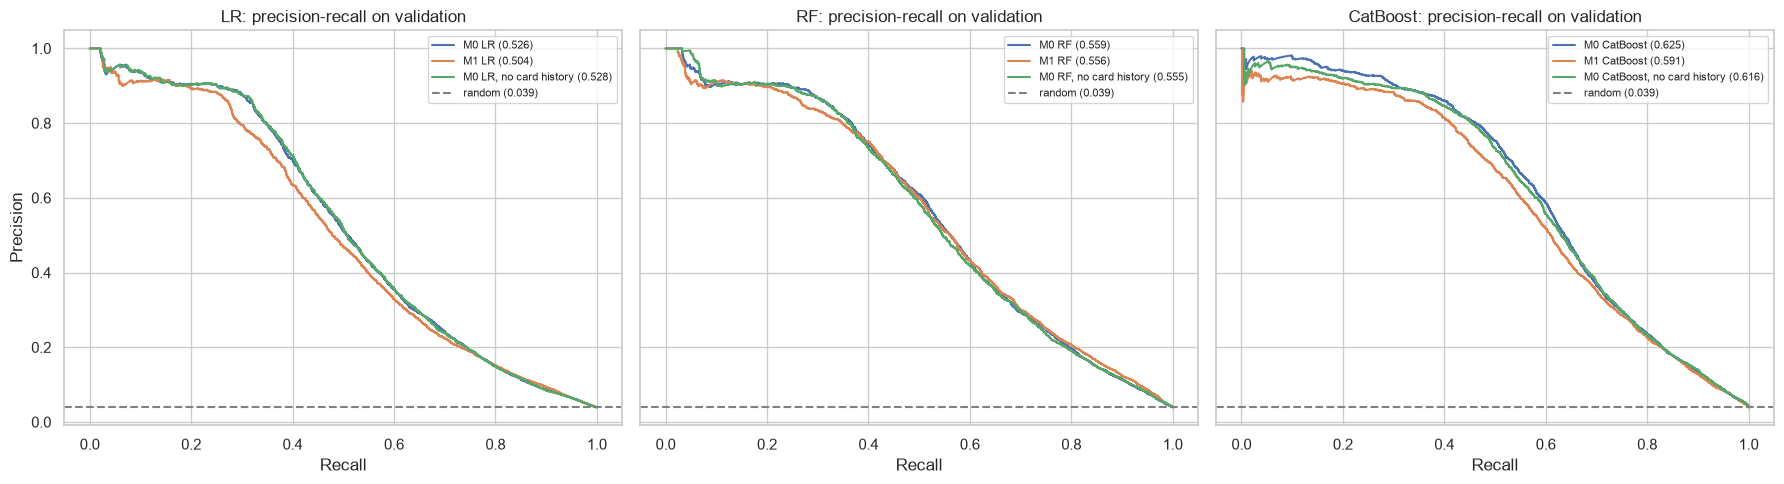

In [20]:
# precision-recall curves on the validation rows
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

curve_names = [
    "M0 {family}",
    "M1 {family}",
    "M0 {family}, no card history",
]
for ax, family in zip(axes, ["LR", "RF", "CatBoost"]):
    for pattern in curve_names:
        name = pattern.format(family=family)
        precision, recall, thresholds = precision_recall_curve(y_val, val_scores[name])
        ax.plot(recall, precision, label=f"{name} ({results_table.loc[name, 'PR-AUC']:.3f})")

    # a model that ranks at random gets the fraud rate
    ax.axhline(y_val.mean(), color="grey", linestyle="--", label=f"random ({y_val.mean():.3f})")
    ax.set_title(f"{family}: precision-recall on validation")
    ax.set_xlabel("Recall")
    ax.legend(fontsize=8)

axes[0].set_ylabel("Precision")
plt.tight_layout()
plt.show()

**Takeaway: Validation Results**
- The family ranking is the same for M0, M1 and M0 without card history => CatBoost > RF > LR

- The best model so far is **M0 CatBoost** (PR-AUC 0.626, ROC-AUC 0.926, precision@100 per day 0.612)

- CatBoost is ahead of RF by 0.067 PR-AUC in M0 and 0.035 in M1. Both gaps are much larger than seed noise (at most 0.006 PR-AUC, Section 5.6), so CatBoost being the strongest family is not just noise. RF is ahead of LR by 0.03 to 0.05

- In the PR curves, all models keep a precision of about 0.9 up to a recall of about 0.2, so the easiest frauds are found by every model. The families mostly differ between recall 0.3 and 0.6. Above a recall of about 0.8 all curves drop to a precision of about 0.1 to 0.2 => the hardest frauds look normal to every model

- Note: these results come from one validation split, and the settings are not tuned. The final family choice for M3 and M4 is made after M2 (Section 9)

## 8. SHAP Values for the M0 CatBoost Model
SHAP values split each prediction into a contribution from each feature, and a positive value pushes the score towards fraud. We use M0 CatBoost, the best model so far (Section 7). We calculate them with CatBoost's built-in SHAP for 5,000 random validation transactions and show:
- The features with the largest mean absolute SHAP value (the features the model relies on most)
- The total mean absolute SHAP value per feature group (groups from Section 6.1)
- The direction of each numeric feature: the Spearman correlation between its value and its SHAP value (positive => higher values push the score towards fraud)

Note: SHAP only describes what this fitted model uses. It does not show whether a feature generalises to later data, so we do not use it to select features. If card-history features rank high here, the model partly relies on recognising the card (Section 6.2 measures how much the score depends on that)

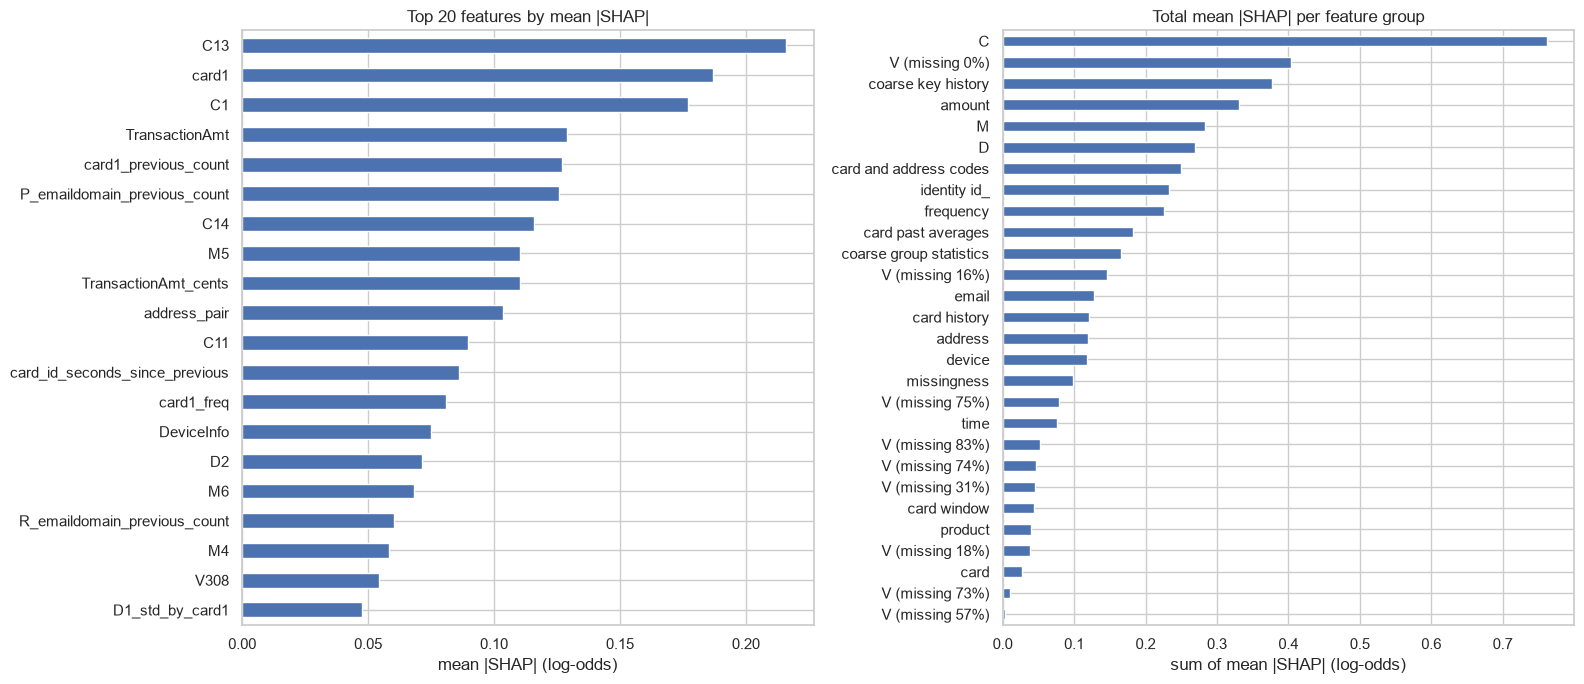

,group,role,mean |SHAP|,value vs SHAP (Spearman)
C13,C,transaction-level,0.216,-0.965
card1,card and address codes,transaction-level,0.187,NaN
C1,C,transaction-level,0.177,0.878
TransactionAmt,amount,transaction-level,0.129,0.959
card1_previous_count,coarse key history,coarse entity aggregate,0.127,0.959
P_emaildomain_previous_count,coarse key history,coarse entity aggregate,0.126,0.827
C14,C,transaction-level,0.116,-0.838
M5,M,transaction-level,0.110,NaN
TransactionAmt_cents,amount,transaction-level,0.110,-0.905
address_pair,address,transaction-level,0.104,NaN


In [21]:
shap_cols = feature_cols   # M0 uses all candidate features
shap_rows = X_val[shap_cols].sample(5000, random_state=SEED)
shap_values = shap_model.get_feature_importance(Pool(shap_rows, cat_features=cat_cols), type="ShapValues")[:, :-1]
shap_values = pd.DataFrame(shap_values, index=shap_rows.index, columns=shap_cols)

mean_abs = shap_values.abs().mean().sort_values(ascending=False)
group_abs = mean_abs.groupby(pd.Series(group_of)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
mean_abs.head(20).iloc[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Top 20 features by mean |SHAP|")
axes[0].set_xlabel("mean |SHAP| (log-odds)")
group_abs.iloc[::-1].plot.barh(ax=axes[1])
axes[1].set_title("Total mean |SHAP| per feature group")
axes[1].set_xlabel("sum of mean |SHAP| (log-odds)")
plt.tight_layout()
plt.show()

# top 20 features by mean |SHAP|, with their group and direction (categorical features have no direction)
top_shap = mean_abs.head(20).rename("mean |SHAP|").to_frame()
top_shap.insert(0, "group", [group_of[c] for c in top_shap.index])
top_shap.insert(1, "role", [group_role.get(group_of[c], "transaction-level") for c in top_shap.index])
top_shap["value vs SHAP (Spearman)"] = [
    pd.Series(shap_rows[c].to_numpy(), dtype="float64").corr(pd.Series(shap_values[c].to_numpy()), method="spearman")
    if c not in cat_cols else np.nan
    for c in top_shap.index
]
display(top_shap.round(3))

**Takeaway: SHAP**
- The features M0 CatBoost relies on most are `C13` (mean |SHAP| 0.216), `card1` (0.187) and `C1` (0.177), then `TransactionAmt` (0.129), `card1_previous_count` (0.127) and `P_emaildomain_previous_count` (0.126). By group, the `C` counts are the largest by far (about 0.76), followed by `V (missing 0%)` (about 0.40), the coarse key history (about 0.38) and the amount (about 0.33)

- Directions of the numeric features:
    - larger amounts push the score towards fraud (`TransactionAmt` 0.96), and so do higher `C1` and `C11` (0.88 and 0.83)
    - higher `C13` and `C14` push it away from fraud (-0.97 and -0.84)
    - a lower `D2` pushes towards fraud (-0.82). `D2` is almost the same as `D1` (Spearman 0.98 in notebook 04), which looks like the days since the card was first used => newer cards look riskier
    - `TransactionAmt_cents` has -0.91 => amounts with fewer cents (e.g. round amounts) push towards fraud
    - more earlier transactions with the same `card1` or email domain push towards fraud (`card1_previous_count` 0.96, `P_emaildomain_previous_count` 0.83). Many cards share these keys, so this describes the code or domain and not one card

- The raw code `card1` is the 2nd most used feature, and `address_pair` and `DeviceInfo` are also in the top 20 => the model uses how risky a specific code is. Many cards share each code, so this is not the same as recognising one card **BUT** the risk of a code can change over time (e.g. if fraud moves to other card types), which M2 will show

- One card-history feature is in the top 20: `card_id_seconds_since_previous` (12th, 0.086), with no clear direction (Spearman -0.05, so its effect depends on the other features). Added up per group the card-history features are smaller (`card past averages` 10th, `card history` 14th, `card window` near the bottom) => this matches Section 6, where removing them costs CatBoost 0.010 PR-AUC

- Note: SHAP only shows what this fitted model uses, not whether a feature still works on later data

## 9. M2: Periodic Retraining
M0 and M1 are trained once and then used for the whole validation period. Fraud patterns can change over time (concept drift), so M2 retrains the model regularly on recent labelled transactions. Notebook 02 already showed that IEEE-CIS changes over time: the daily fraud rate moves between about 1% and 7% (*Transaction amount, relative time*), and many `C` and `D` columns shift between the earliest and latest days (*Distribution shifts over time*)

M2 is built on **M0**, since class weights (M1) lowered PR-AUC for every family in Section 5 => the only change from M0 to M2 is the retraining. We keep the M0 settings for each family (LR, RF and CatBoost), and tuning is done after M2 (notebook 07)

This section covers:
- **Label delay**: a transaction's label (fraud or not) is only known some time later, once the chargeback is confirmed. We assume **7 days**, so each retrain can only use transactions that are at least 7 days old. The last 7 days before each retrain are unlabelled, which is the gap M3 later tries to use. We also run a **0-day** delay as a reference, to show what the delay costs. Notebook 03 (Section 8) found that 87.7% of fraud cards have all their fraud within 7 days, but some last much longer (up to 181 days) => 7 days covers most but not all fraud, so longer delays can be tested later during tuning

- **Retraining settings** (Section 9.2): how often to retrain (every 7 or 14 days) and how much history to train on (the last 28 days, the last 56 days or all earlier days). These are chosen by simulating the retraining on the **training days**, so the validation rows are not used to choose

- **Static vs M2** (Sections 9.3 and 9.4): a static model is trained once before the validation period and never updated, while M2 is retrained with the frequency and window chosen in Section 9.2 (every 7 days for all three families). Both only use labels that are at least 7 days old, so the only difference is the retraining. We compare their PR-AUC over all validation rows and for each validation week

### 9.1 Retraining Setup
The scoring period is split into blocks of `frequency` days. Before each block, the model is retrained and then scores the block's transactions:
- **Label delay**: at the start of a block on day `d`, only transactions before day `d - delay` have labels, so the model trains on those only. The blocks work in whole days => with the 7-day delay a block starting on day 109 trains on days up to 101, and with the 0-day delay on days up to 108 (up to the end of the day before the block)

- **Window**: the model trains on the last `window` days of labelled transactions (28 or 56), or on all labelled transactions (`"all"`)

- A **static** model is the same thing with a single block, so it is trained once and scores the whole period

- Note: this is not the same cut as M0. The split in notebook 04 is made by row count, so day 109 has training rows early in the day and validation rows later in the day. M0 trains on all training rows, including those on day 109, but the static and M2 runs never use day 109 for the first block, even with the 0-day delay

We first put the training and validation rows into one frame (`X`, `y`), with the day of each row and masks for the two splits. `retrain_scores` trains on `labelled_rows` only and returns one score per scored row. The scores of each run are saved in `data/interim/m2_scores/`, so a rerun loads the runs that already finished instead of training them again

In [22]:
LABEL_DELAY_DAYS = 7

# scores of every retraining run are saved here, so a rerun can skip the runs that already finished
SCORES_DIR = Path("../data/interim/m2_scores")
SCORES_DIR.mkdir(parents=True, exist_ok=True)

# training and validation rows in one frame, in time order, with the day of each row
day = np.concatenate([(train["TransactionDT"] // 86400).to_numpy(), val_day])
del train, val, shap_model, shap_rows, shap_values
X, y = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
del X_train, X_val
is_train = np.arange(len(X)) < len(y_train)
is_val = ~is_train
print("training rows:", is_train.sum(), ", days", day[is_train].min(), "to", day[is_train].max())
print("validation rows:", is_val.sum(), ", days", day[is_val].min(), "to", day[is_val].max())

training rows: 377945 , days 1 to 109
validation rows: 94487 , days 109 to 141


In [23]:
def retrain_scores(family, run_name, labelled_rows, score_rows, first_day, last_day, frequency, window, delay):
    path = SCORES_DIR / f"{run_name}.pkl"
    if path.exists():
        return pd.read_pickle(path).loc[X.index[score_rows]]

    start = time.time()
    scores = pd.Series(np.nan, index=X.index[score_rows], dtype="float64")
    n_models = 0
    for block_start in range(first_day, last_day + 1, frequency):
        block = score_rows & (day >= block_start) & (day < block_start + frequency)
        if not block.any():
            continue

        # labelled rows: before the block start minus the label delay, inside the window
        label_end = block_start - delay
        fit_rows = labelled_rows & (day < label_end)
        if window != "all":
            fit_rows &= day >= label_end - window

        model = clone(models[family]).set_params(**base_settings[family])   # M0 settings, no class weights
        if family == "CatBoost":
            model.fit(X[fit_rows], y[fit_rows], cat_features=cat_cols)
        else:
            model.fit(X[fit_rows], y[fit_rows])
        scores[X.index[block]] = model.predict_proba(X[block])[:, 1]
        del model
        n_models += 1

    scores.to_pickle(path)
    print(f"{run_name}: {n_models} models ({time.time() - start:.0f}s)")
    return scores

### 9.2 Choosing the Retraining Settings on the Training Days
We simulate the retraining on the **training rows only**, scoring the training days from day 81 to the end of the training period (about 4 weeks), with the 7-day label delay:
- Day 81 leaves at least 56 days of labelled history before the first block, so every window has its full length (80 - 7 = 73 days before the first block)

- For each family we try every combination of frequency (7, 14 days) and window (28, 56, all), and pool the scores of all blocks into one PR-AUC

- For each family we keep the combination with the highest PR-AUC. The validation rows are not used for this choice

Note: only training rows are used for training and scoring here, so the simulation never sees the validation rows

Why we try these settings (from notebooks 02 and 03):
- **Window**: the earlier days look different from the later ones. The daily fraud rate is lower in roughly the first 25 days (about 2-3%, vs mostly 3-5% afterwards, notebook 02 *Transaction amount, relative time*), `W` grows from 54.7% of transactions in the first 30 days to about 80% afterwards (notebook 02 *Identity table*), and several columns shift over time e.g. `C9` with a KS statistic of 0.29 (notebook 02 *Distribution shifts over time*) => a shorter window (28 or 56 days) only learns from days that look like the scored days **BUT** all earlier days give more fraud rows to learn from, so we test both

- **Frequency**: fraud on a card is usually short-lived. The median fraud card only has 1 fraud transaction, and 87.7% of fraud cards have all their fraud within 7 days (notebook 03, Section 8) => if the fraud patterns change quickly, retraining every 7 days instead of 14 could help

- **Label delay**: the 7-day delay comes from the same check (notebook 03, Section 8), see Section 9

In [24]:
SIM_FIRST_DAY = 81
sim_rows = is_train & (day >= SIM_FIRST_DAY)
sim_last_day = int(day[is_train].max())
print(f"scored rows in the simulation: {sim_rows.sum()} (days {SIM_FIRST_DAY} to {sim_last_day}, fraud rate {y[sim_rows].mean() * 100:.2f}%)")

FREQUENCIES = [7, 14]
WINDOWS = [28, 56, "all"]

sim_results = []
for family in ["LR", "RF", "CatBoost"]:
    for frequency in FREQUENCIES:
        for window in WINDOWS:
            run_name = f"sim_{family}_freq{frequency}_window{window}_delay{LABEL_DELAY_DAYS}"
            # only training rows can be used for training here (the validation rows come later)
            scores = retrain_scores(family, run_name, is_train, sim_rows, SIM_FIRST_DAY, sim_last_day, frequency, window, LABEL_DELAY_DAYS)
            sim_results.append({"family": family, "frequency": frequency, "window": window,
                                "PR-AUC": average_precision_score(y[sim_rows], scores)})

sim_table = pd.DataFrame(sim_results)
display(sim_table.pivot_table(index=["family", "frequency"], columns="window", values="PR-AUC", sort=False).round(4))

best_retrain = {}
for family in ["LR", "RF", "CatBoost"]:
    best = sim_table[sim_table["family"] == family].sort_values("PR-AUC", ascending=False).iloc[0]
    best_retrain[family] = {"frequency": int(best["frequency"]), "window": best["window"]}
    print(f"{family}: retrain every {best['frequency']} days on window {best['window']} (simulation PR-AUC {best['PR-AUC']:.4f})")

scored rows in the simulation: 92519 (days 81 to 109, fraud rate 3.59%)


window                  28      56     all
family   frequency                        
LR       7          0.4194  0.4586  0.4539
         14         0.4105  0.4536  0.4464
RF       7          0.4683  0.4886  0.5008
         14         0.4678  0.4868  0.4951
CatBoost 7          0.5461  0.5495  0.5575
         14         0.5317  0.5357  0.5439

LR: retrain every 7 days on window 56 (simulation PR-AUC 0.4586)
RF: retrain every 7 days on window all (simulation PR-AUC 0.5008)
CatBoost: retrain every 7 days on window all (simulation PR-AUC 0.5575)


**Takeaway: Retraining Settings**
- **Retraining every 7 days is never worse than every 14 days**. The gain is largest for CatBoost (+0.014 PR-AUC for every window) and smallest for RF (+0.0005 to +0.006) => labels that are a week fresher help, which fits notebook 03 (Section 8), where most fraud on a card is over within 7 days

- **More history helps**: the 28-day window is the worst for every family. RF and CatBoost do best on all earlier days, and LR does best on the last 56 days (0.459 vs 0.454 for all days) => the changes over time from notebook 02 (*Distribution shifts over time*, *Identity table*) do not make the older days harmful for the trees, and having more fraud rows to learn from seems to matter more

- Chosen settings: **LR every 7 days on the last 56 days, RF and CatBoost every 7 days on all earlier days**

- Some gaps are within seed noise (e.g. RF 7 vs 14 days on the 28-day window, 0.0005), so the order of the close settings may change with another seed **BUT** the 7-day frequency wins in all 9 family and window pairs

- The simulation PR-AUC values are lower than the validation ones, since they score other days with less labelled history => only compare them with each other

- Cost: more frequent retraining on more history is the slowest e.g. CatBoost every 7 days on all days took 48 minutes in the simulation vs 13 minutes on the last 28 days

### 9.3 Static vs M2 on the Validation Rows
For each family we score the validation rows (days 109 to 141) four ways:
1. **Static, 7-day delay**: trained once on the labelled transactions before day 109 - 7 = 102, with the window from Section 9.2

2. **M2, 7-day delay** (main result): retrained with the frequency and window from Section 9.2. Each retrain can also use the validation transactions that are at least 7 days old

3. **Static, 0-day delay** and 4. **M2, 0-day delay** (reference): the same with each day's labels available once the day is over, to show how much the delay costs

The static and M2 models use the same window, so the only difference between them is the retraining

In [25]:
VAL_FIRST_DAY, VAL_LAST_DAY = int(day[is_val].min()), int(day[is_val].max())
n_days = VAL_LAST_DAY - VAL_FIRST_DAY + 1

m2_scores = {}   # validation scores of the static and M2 runs
for family in ["LR", "RF", "CatBoost"]:
    frequency, window = best_retrain[family]["frequency"], best_retrain[family]["window"]
    for delay in [LABEL_DELAY_DAYS, 0]:
        print(f"{family}, delay {delay}:")
        # static: one block covering the whole validation period
        m2_scores[f"static {family}, delay {delay}"] = retrain_scores(
            family, f"val_static_{family}_window{window}_delay{delay}", is_train | is_val, is_val, VAL_FIRST_DAY, VAL_LAST_DAY, n_days, window, delay).to_numpy()
        m2_scores[f"M2 {family}, delay {delay}"] = retrain_scores(
            family, f"val_m2_{family}_freq{frequency}_window{window}_delay{delay}", is_train | is_val, is_val, VAL_FIRST_DAY, VAL_LAST_DAY, frequency, window, delay).to_numpy()

LR, delay 7:
LR, delay 0:
RF, delay 7:
RF, delay 0:
CatBoost, delay 7:
CatBoost, delay 0:


### 9.4 M2 Results
The four runs per family side by side, then the change from static to M2, then PR-AUC per validation week

In [26]:
m2_table = pd.DataFrame([evaluate(name, scores) for name, scores in m2_scores.items()]).set_index("model")
display(m2_table.round(4))

# change from static to M2 for each family and delay (M2 - static)
rows = []
for family in ["LR", "RF", "CatBoost"]:
    for delay in [LABEL_DELAY_DAYS, 0]:
        static, m2 = m2_table.loc[f"static {family}, delay {delay}"], m2_table.loc[f"M2 {family}, delay {delay}"]
        rows.append({"family": family, "delay": delay} | {metric: m2[metric] - static[metric] for metric in metric_cols})
print("change from static to M2 (M2 - static):")
display(pd.DataFrame(rows).set_index(["family", "delay"]).round(4))

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day,TP,FP,FN,TN
model,,,,,,,,,,
"static LR, delay 7",0.5012,0.8706,0.7585,0.3383,0.4679,0.5109,1253,399,2451,90384
"M2 LR, delay 7",0.5103,0.8789,0.7306,0.3515,0.4747,0.5127,1302,480,2402,90303
"static LR, delay 0",0.5005,0.8802,0.7232,0.3626,0.4830,0.5082,1343,514,2361,90269
"M2 LR, delay 0",0.5323,0.8856,0.7686,0.3739,0.5031,0.5361,1385,417,2319,90366
"static RF, delay 7",0.5429,0.9036,0.8782,0.2746,0.4183,0.5418,1017,141,2687,90642
"M2 RF, delay 7",0.5643,0.9115,0.8767,0.2765,0.4204,0.5564,1024,144,2680,90639
"static RF, delay 0",0.5561,0.9082,0.8825,0.2778,0.4226,0.5518,1029,137,2675,90646
"M2 RF, delay 0",0.5845,0.9174,0.8808,0.2873,0.4332,0.5736,1064,144,2640,90639
"static CatBoost, delay 7",0.6024,0.9239,0.8099,0.4152,0.5490,0.5918,1538,361,2166,90422


change from static to M2 (M2 - static):


PR-AUC  ROC-AUC  precision  recall      F1  \
family   delay                                               
LR       7      0.0092   0.0083    -0.0278  0.0132  0.0068   
         0      0.0318   0.0054     0.0454  0.0113  0.0201   
RF       7      0.0214   0.0080    -0.0015  0.0019  0.0020   
         0      0.0284   0.0091    -0.0017  0.0094  0.0106   
CatBoost 7      0.0488   0.0083     0.0330  0.0324  0.0357   
         0      0.0794   0.0170     0.0457  0.0610  0.0618   

                precision@100 per day  
family   delay                         
LR       7                     0.0018  
         0                     0.0279  
RF       7                     0.0145  
         0                     0.0218  
CatBoost 7                     0.0406  
         0                     0.0633

week,1,2,3,4,5
model,,,,,
"static LR, delay 7",0.5516,0.5279,0.5546,0.4316,0.3218
"M2 LR, delay 7",0.5516,0.5181,0.5632,0.4836,0.3547
"static LR, delay 0",0.5570,0.5181,0.5557,0.4326,0.3354
"M2 LR, delay 0",0.5570,0.5589,0.5719,0.5074,0.3659
"static RF, delay 7",0.5938,0.5767,0.5986,0.4346,0.4010
"M2 RF, delay 7",0.5938,0.5869,0.6151,0.4964,0.4476
"static RF, delay 0",0.6126,0.5869,0.6108,0.4480,0.4131
"M2 RF, delay 0",0.6126,0.6012,0.6328,0.5206,0.4814
"static CatBoost, delay 7",0.6705,0.6136,0.6328,0.5327,0.4568


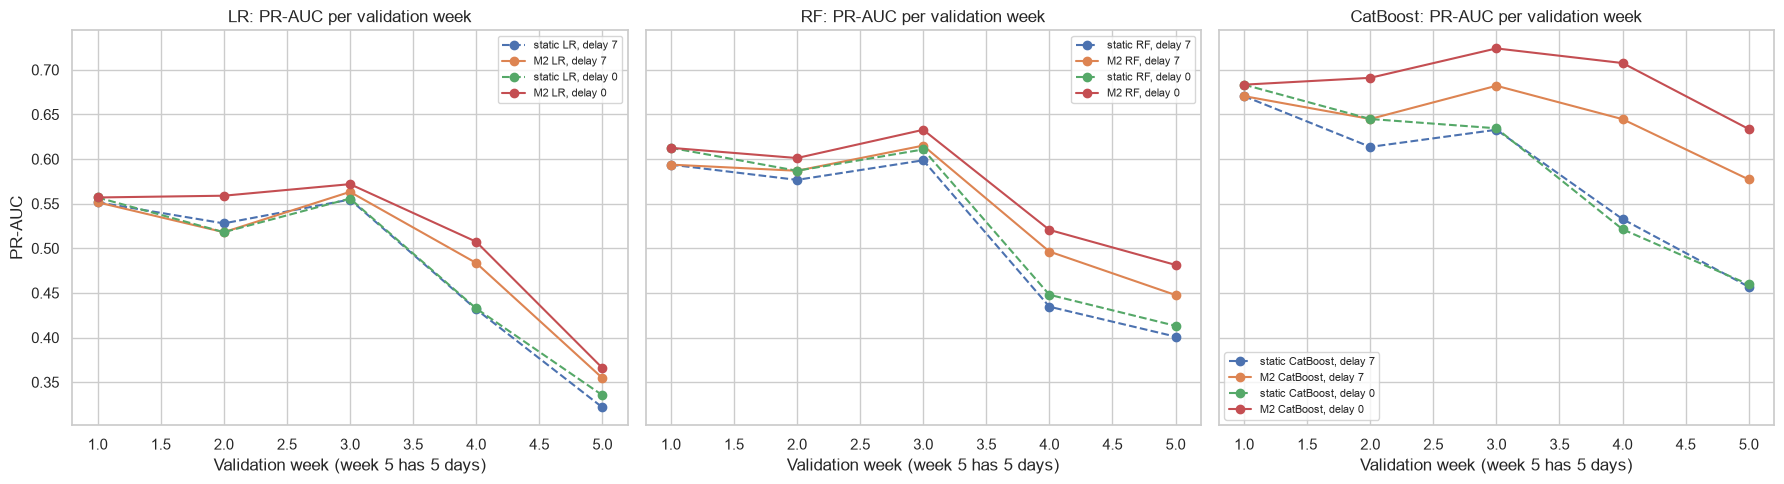

In [27]:
# PR-AUC per validation week: does the static model get worse over time and whether M2 can keep up
week = (val_day - VAL_FIRST_DAY) // 7
weekly = []
for name, scores in m2_scores.items():
    for w in np.unique(week):
        rows_w = week == w
        weekly.append({"model": name, "week": int(w) + 1, "PR-AUC": average_precision_score(y_val.to_numpy()[rows_w], scores[rows_w]),
                       "rows": int(rows_w.sum()), "fraud rate": y_val.to_numpy()[rows_w].mean()})
weekly = pd.DataFrame(weekly)
display(weekly.pivot_table(index="model", columns="week", values="PR-AUC", sort=False).round(4))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, family in zip(axes, ["LR", "RF", "CatBoost"]):
    for name in [f"static {family}, delay {LABEL_DELAY_DAYS}", f"M2 {family}, delay {LABEL_DELAY_DAYS}",
                 f"static {family}, delay 0", f"M2 {family}, delay 0"]:
        data = weekly[weekly["model"] == name]
        ax.plot(data["week"], data["PR-AUC"], marker="o", linestyle="-" if name.startswith("M2") else "--", label=name)
    ax.set_title(f"{family}: PR-AUC per validation week")
    ax.set_xlabel("Validation week (week 5 has 5 days)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("PR-AUC")
plt.tight_layout()
plt.show()

**Takeaway: Static vs M2**
- **M2 beats the static model for every family** with the 7-day label delay: CatBoost 0.602 to 0.651 (+0.049), RF 0.543 to 0.564 (+0.021) and LR 0.501 to 0.510 (+0.009). The CatBoost and RF gains are well above seed noise (at most 0.006, Section 5.6), and the LR gain is small

- M2 CatBoost with the 7-day delay (0.651) also beats M0 CatBoost (0.626, Section 4), which was trained once with no label delay

- **The gain comes from the later weeks**: week 1 is the same for both (the first block uses the same model), then the static model gets worse while M2 keeps up. Static CatBoost drops from 0.671 in week 1 to 0.457 in week 5, and M2 is still at 0.577 in week 5 => M2 can handle the drift (Note: the fraud rate also differs between weeks, so only compare models within the same week)

- At 0.5, M2 CatBoost catches more fraud than static (1,658 vs 1,538) with fewer false alarms (309 vs 361), and precision@100 per day goes from 0.592 to 0.632

- **The 7-day delay costs M2 a lot**: M2 CatBoost gets 0.693 with immediate labels vs 0.651 with the 7-day delay (-0.041), RF -0.020 and LR -0.022. For the static model the delay costs less (CatBoost -0.011) => when retraining often, the most recent labelled week matters most => M3 tries to recover with the unlabelled last 7 days

- Check: in week 2, M2 with the 7-day delay has exactly the same PR-AUC as static with the 0-day delay (e.g. CatBoost 0.6449), since both train on the labels before day 109 => the label delay works as intended

- Note: static CatBoost with the 0-day delay (0.613) is below M0 CatBoost (0.626), although both are trained once on the labels before the validation period. The split in notebook 04 is made by row count, so day 109 has training rows early in the day and validation rows later in the day. M0 uses those training rows, but the static run only trains on whole days before the first block (day 109) => these most recent rows seem to matter. This only affects the comparison with M0, since the static and M2 runs both use whole days

- Cost: M2 CatBoost needs 5 models and took 72 minutes, vs 11 minutes for the static model

### 9.5 Check: LR on All Earlier Days
In Section 9.2, LR was the only family that chose the last 56 days instead of all earlier days, and the gap was small (0.459 vs 0.454). To check that this choice does not change the LR result, we repeat the 7-day delay runs for LR with all earlier days, the same window as RF and CatBoost
- If static vs M2 gives about the same gain with both windows, the LR result does not depend on the window

- Note: M0 LR is trained on all training days, so this also shows how much of the drop from M0 LR to static LR comes from the shorter window and how much from the label delay

In [28]:
# LR with all earlier days (the window of RF and CatBoost), 7-day delay, retrained every 7 days as in Section 9.2
frequency = best_retrain["LR"]["frequency"]
window_check = {
    "static LR, window 56": m2_scores[f"static LR, delay {LABEL_DELAY_DAYS}"],
    "M2 LR, window 56": m2_scores[f"M2 LR, delay {LABEL_DELAY_DAYS}"],
    "static LR, window all": retrain_scores("LR", f"val_static_LR_windowall_delay{LABEL_DELAY_DAYS}", is_train | is_val, is_val,
                                            VAL_FIRST_DAY, VAL_LAST_DAY, n_days, "all", LABEL_DELAY_DAYS).to_numpy(),
    "M2 LR, window all": retrain_scores("LR", f"val_m2_LR_freq{frequency}_windowall_delay{LABEL_DELAY_DAYS}", is_train | is_val, is_val,
                                        VAL_FIRST_DAY, VAL_LAST_DAY, frequency, "all", LABEL_DELAY_DAYS).to_numpy(),
}
window_table = pd.DataFrame([evaluate(name, scores) for name, scores in window_check.items()]).set_index("model")
display(window_table[metric_cols].round(4))

# change from static to M2 for each window (M2 - static)
for window in ["56", "all"]:
    gain = window_table.loc[f"M2 LR, window {window}", "PR-AUC"] - window_table.loc[f"static LR, window {window}", "PR-AUC"]
    print(f"window {window}: M2 - static = {gain:+.4f} PR-AUC")
print(f"M0 LR (all training days, no delay): {average_precision_score(y_val, val_scores['M0 LR']):.4f} PR-AUC")

,PR-AUC,ROC-AUC,precision,recall,F1,precision@100 per day
model,,,,,,
"static LR, window 56",0.5012,0.8706,0.7585,0.3383,0.4679,0.5109
"M2 LR, window 56",0.5103,0.8789,0.7306,0.3515,0.4747,0.5127
"static LR, window all",0.5207,0.8814,0.7776,0.3588,0.4910,0.5261
"M2 LR, window all",0.5331,0.8880,0.7865,0.3631,0.4969,0.5330


window 56: M2 - static = +0.0092 PR-AUC
window all: M2 - static = +0.0124 PR-AUC
M0 LR (all training days, no delay): 0.5265 PR-AUC


**Takeaway: LR Window Check**
- **M2 still beats static with all earlier days**: LR 0.521 to 0.533 (+0.012), vs 0.501 to 0.510 (+0.009) on the last 56 days => the retraining gain for LR does not depend on the window, and it is still the smallest of the three families (RF +0.021, CatBoost +0.049)

- **BUT on the validation rows all earlier days is better for LR**: static 0.521 vs 0.501 (+0.020) and M2 0.533 vs 0.510 (+0.023). In the simulation the last 56 days was slightly better (0.459 vs 0.454), so this small gap from Section 9.2 does not carry over to the validation period => for LR the window is not a clear choice, and all earlier days is at least as good

- With all earlier days, M2 LR (0.533) also beats M0 LR (0.527), like CatBoost does. Static LR on all earlier days (0.521) is only 0.006 below M0 LR => most of the drop from M0 LR to static LR in Section 9.4 (0.527 to 0.501) comes from the shorter window, and only a little from the 7-day delay and leaving out day 109